# Инфополя · копия с проверками распределений

Копия исходного [ноутбука по инфополям](выбор%20сегмента%20для%20обучения.ipynb).
Исходный расчёт воспроизводится на своём снимке из 18 860 строк. Дополнение в конце
использует 23 036 строк из снимка утверждённых паспортов, чтобы его результаты были
сопоставимы с зарплатным ноутбуком. Оба CSV берутся из истории Git с проверкой SHA-256.

Новые результаты находятся в разделах 9–10 в конце ноутбука.

Для повторного запуска нужен полный Git-клон. Откройте ноутбук из `Analytics/`
или из корня репозитория. Расчёт выполнен на pandas 2.3.3, NumPy 2.3.3,
SciPy 1.18.1 и statsmodels 0.14.6. Также требуются Jupyter, matplotlib, Jinja2 и tabulate.

# «Анализ признаков», зона Насти
Качество колонок, категориальные фичи, география, концентрация работодателей и правила укрупнения сегментов.

In [1]:
import re
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

from pathlib import Path
import sys

analytics = Path("Analytics") if Path("Analytics").is_dir() else Path.cwd()
sys.path.insert(0, str(analytics.resolve()))

from segment_normality import (
    ALPHA, MIN_TEST_N, PRIORITY, REJECT, SEGMENT_KEYS,
    holm, lilliefors_row, load_snapshot, priority_vacancies,
)

import warnings
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

df, dataset_source, dataset_hash = load_snapshot("info")
print(f"Источник: {dataset_source}\nSHA-256: {dataset_hash}")
results = {}
print(df.shape)

Источник: 6d1e0cfe560a212b32579dc32ce8a100ba85040b:Data/dataset/vacancies.csv
SHA-256: 24350fd63bceb2f549009ae9842aaaf3bbdca6f918a46873c692c0ce58c4c3c9
(18860, 120)


## 0. Предобработка
В значениях параметров встречаются неразрывные пробелы (`\xa0`): из-за этого «Раз в неделю» и «Раз в неделю» считаются разными категориями.
Перед любым анализом нормализуем пробелы во всех текстовых колонках (кроме длинных текстов).

In [2]:
TEXT_COLS = ["description", "location_observed", "city__evidence", "read_limitations"]
str_cols = [c for c in df.columns if pd.api.types.infer_dtype(df[c], skipna=True) == "string"]

nbsp_share = {c: df[c].astype(str).str.contains(" ").mean() for c in str_cols}
nbsp_share = pd.Series(nbsp_share).loc[lambda s: s > 0].sort_values(ascending=False).round(4)
print("Доля значений с неразрывным пробелом:\n", nbsp_share.head(10))

for c in str_cols:
    if c in TEXT_COLS:
        continue
    df[c] = df[c].str.replace(r"[  ]", " ", regex=True).str.strip()

print("\nЧастота выплат после нормализации:\n", df["Частота выплат"].value_counts(dropna=False))

Доля значений с неразрывным пробелом:
 salary_raw                    1.0000
views_total                   0.9914
views_today                   0.9914
description                   0.1593
Частота выплат                0.0059
В том числе для кандидатов    0.0052
Что получают работники        0.0045
Способ оформления             0.0036
Ассортимент                   0.0008
Вид доставки                  0.0006
dtype: float64



Частота выплат после нормализации:
 Частота выплат
Дважды в месяц      8646
Раз в неделю        4144
Каждый день         2450
NaN                 1548
Раз в месяц         1356
Три раза в месяц     716
Name: count, dtype: int64


## 1. Заполненность 120 признаков и группы Core / Sparse / Dead
Пропуск = `NaN`. Пустых строк и заглушек вида «Не указано» в датасете нет (проверено)

In [3]:
first_param, last_param = "График", "Знание графических программ"
param_cols = list(df.columns[df.columns.get_loc(first_param): df.columns.get_loc(last_param) + 1])

SERVICE = {"source", "id", "source_url", "observed_at", "date_raw", "views_total", "views_today",
           "listing_rank", "listing_promoted", "full_parameters_read", "analysis_status",
           "export_eligibility", "read_status_parameters", "read_status_description",
           "read_status_location", "read_limitations", "read_status_employer", "city__source",
           "city__evidence", "city_anomaly", "military_rule_version", "first_seen_at", "last_seen_at",
           "run_id", "run_ids", "enrichment_status", "enriched_fields", "enrichment_version",
           "employer_profile_url", "segments"}
TEXT = {"title", "description"}
TARGET = {"salary_raw"}


def col_role(c):
    if c in param_cols:
        return "параметр карточки"
    if c in SERVICE:
        return "служебная"
    if c in TEXT:
        return "текст (зона Кости)"
    if c in TARGET:
        return "таргет (трек зарплат)"
    return "гео / профессия / работодатель / флаги"


def fill_group(x):
    if x > 0.85:
        return "Core"
    if x >= 0.20:
        return "Sparse"
    return "Dead"


fill = pd.DataFrame({
    "fill_rate": df.notna().mean(),
    "n_filled": df.notna().sum(),
    "n_unique": df.nunique(),
})
fill["group"] = fill["fill_rate"].apply(fill_group)
fill["role"] = [col_role(c) for c in fill.index]
fill["constant"] = fill["n_unique"] <= 1          # заполнено, но не несёт информации
fill = fill.sort_values("fill_rate", ascending=False)

print(f"Всего колонок: {len(fill)}")
print(pd.crosstab(fill["role"], fill["group"], margins=True))

Всего колонок: 120
group                                   Core  Dead  Sparse  All
role                                                           
гео / профессия / работодатель / флаги     4     1       2    7
параметр карточки                          5    70       7   82
служебная                                 24     3       1   28
таргет (трек зарплат)                      1     0       0    1
текст (зона Кости)                         2     0       0    2
All                                       36    74      10  120


### 1.1. Условная заполненность по профессиям
Многие параметры «мёртвые» на всём датасете, потому что относятся только к одной профессии
(например, «Категория водительских прав» нужна только водителям). Поэтому для каждого параметра
считаем заполненность внутри каждой профессии: если внутри какой-то профессии она > 85% — признак
профессионально-специфичный и годится для модели этой профессии.

In [4]:
df["profession_clean"] = df["profession"].str.split(";").str[0].str.strip()   # «Продавец; Кассир» -> «Продавец» (2 строки)
df["profession_filled"] = df["profession_clean"].fillna("не определена")

by_prof_fill = df.groupby("profession_filled")[param_cols].apply(lambda g: g.notna().mean()).T
by_prof_fill.columns.name = None

fill["best_prof_fill"] = by_prof_fill.max(axis=1).reindex(fill.index)
fill["best_prof"] = by_prof_fill.idxmax(axis=1).reindex(fill.index)


def final_group(row):
    if row["role"] != "параметр карточки":
        return row["group"]
    if row["group"] != "Core" and row["best_prof_fill"] > 0.85:
        return f"Prof-Core ({row['best_prof']})"
    if row["group"] == "Dead" and row["best_prof_fill"] >= 0.20 and row["best_prof"] != "не определена":
        return f"Prof-Sparse ({row['best_prof']})"
    return row["group"]


fill["group_with_profession"] = fill.apply(final_group, axis=1)
params_fill = fill[fill["role"] == "параметр карточки"]
print(params_fill["group_with_profession"].value_counts())
print("\nКлючевые параметры:")
print(fill.loc[param_cols[:12], ["fill_rate", "group", "best_prof", "best_prof_fill", "group_with_profession"]].round(3))

flag_params = fill[(fill["role"] == "параметр карточки") & (fill["n_unique"] == 1) & (fill["n_filled"] >= 50)]
print("\nОдно-значные параметры (-> бинарный флаг, NaN = 0):")
print(flag_params[["fill_rate"]].assign(value=[df[c].dropna().iloc[0] for c in flag_params.index]))
fill.loc[flag_params.index, "group_with_profession"] = "Флаг (NaN = нет)"

results["1_fill_rate"] = fill.reset_index(names="column")
results["1b_fill_by_profession"] = by_prof_fill.round(3).reset_index(names="column")

group_with_profession
Dead                                           60
Sparse                                          6
Core                                            5
Prof-Sparse (Водитель грузового транспорта)     5
Prof-Sparse (Курьер)                            3
Prof-Core (Продавец)                            1
Prof-Sparse (Кассир)                            1
Prof-Sparse (Грузчик)                           1
Name: count, dtype: int64

Ключевые параметры:
                                 fill_rate   group                      best_prof  best_prof_fill group_with_profession
График                               1.000    Core  Водитель грузового транспорта           1.000                  Core
Занятость                            1.000    Core  Водитель грузового транспорта           1.000                  Core
Способ оформления                    0.763  Sparse                       Продавец           0.868  Prof-Core (Продавец)
Количество рабочих часов в день      0.634  Sparse 

In [5]:
# Заполненность ключевых параметров в профессиях из каталога (6 массовых профессий)
key_params = ["График", "Занятость", "Опыт работы", "Частота выплат", "Количество рабочих часов в день",
              "Смены", "Способ оформления", "Что получают работники", "Медкнижка",
              "Категория водительских прав", "Длительность вахты", "Формат работы"]
print(by_prof_fill.loc[key_params].round(2))

                                 Водитель грузового транспорта  Грузчик  Кассир  Комплектовщик  Курьер  Продавец  не определена
График                                                    1.00     1.00    1.00           1.00    1.00      1.00           1.00
Занятость                                                 1.00     1.00    1.00           1.00    1.00      1.00           1.00
Опыт работы                                               1.00     1.00    1.00           1.00    1.00      1.00           1.00
Частота выплат                                            0.90     0.95    0.96           0.96    0.93      0.96           0.88
Количество рабочих часов в день                           0.51     0.74    0.68           0.60    0.69      0.55           0.66
Смены                                                     0.09     0.27    0.50           0.23    0.12      0.48           0.15
Способ оформления                                         0.76     0.80    0.86           0.77    0.70  

## 2. Технические аномалии
### 2.1. Пропуски города (location_missing)

In [6]:
is_remote = df["Формат работы"].fillna("").str.contains("Удалённо") | df["run_id"].str.startswith("remote")
is_vahta = df["График"].eq("Вахта")

city_missing = df["city"].isna()
region_missing = df["region"].isna()


def missing_reason(r):
    if pd.notna(r["city"]):
        return "город есть"
    if r["_remote"]:
        return "удалёнка (город не применим)"
    if pd.notna(r["region"]) and r["city__source"] == "missing":
        return "сбой гео-парсера: регион есть, город не распознан"
    if pd.isna(r["region"]) and r["_vahta"]:
        return "вахта без региона"
    if pd.isna(r["region"]):
        return "нет ни города, ни региона"
    return "прочее"


df["_remote"], df["_vahta"] = is_remote, is_vahta
df["city_missing_reason"] = df.apply(missing_reason, axis=1)
reason_tbl = df["city_missing_reason"].value_counts().to_frame("n")
reason_tbl["share"] = (reason_tbl["n"] / len(df)).round(3)
print(f"Город пропущен: {city_missing.mean():.1%}, регион пропущен: {region_missing.mean():.1%}")
print(reason_tbl)
results["2a_city_missing_reason"] = reason_tbl.reset_index(names="reason")

Город пропущен: 32.1%, регион пропущен: 11.3%
                                                       n  share
city_missing_reason                                            
город есть                                         12811  0.679
сбой гео-парсера: регион есть, город не распознан   3447  0.183
удалёнка (город не применим)                        1907  0.101
вахта без региона                                    665  0.035
нет ни города, ни региона                             30  0.002


**Восстановление города.** Для городов федерального значения (Москва, СПб) город = регион:
«Шушары», «Колпино», «Пушкин», «пр. Воскресенские Ворота» и т.п. — это районы и улицы внутри города,
парсер просто не знал этих компонентов. Для остальных берём первый «городской» токен из `location_observed`.

In [7]:
FEDERAL = {"Москва", "Санкт-Петербург", "Севастополь"}
ADMIN = re.compile(r"(обл\.|область|г\.о\.|р-н|район|\bАО\b|Югра|край|Республика|поселение|муниципальный округ|"
                   r"городской округ|сельсовет)", re.IGNORECASE)
STREET = re.compile(r"(ул\.|улица|пр\.|пр-т|проспект|ш\.|шоссе|наб\.|пер\.|бул\.|пл\.|мкр|территория|СНТ|СТ |"
                    r"\d|МКАД|КАД|проезд|тупик|аллея|парк|станция|км\b|б-р|зона|мкр-н)", re.IGNORECASE)
SETTLEMENT_PREFIX = re.compile(r"^(муниципальное образование|городское поселение|г\.|пгт\.?|пос\.|п\.|д\.|с\.|рп\.?|ст-ца)\s+",
                               re.IGNORECASE)


def city_from_location(loc):
    """Последний населённый пункт перед улицей: 'Тюменская обл., ХМАО, Нефтеюганск, пр. 5П' -> 'Нефтеюганск'."""
    if not isinstance(loc, str):
        return np.nan
    cand = np.nan
    for tok in [t.strip() for t in loc.split(",")]:
        first = tok.split(" ")[0]
        if first in FEDERAL:
            return first
        if STREET.search(tok):
            break
        tok = SETTLEMENT_PREFIX.sub("", tok)
        if tok and not ADMIN.search(tok) and len(tok) > 2:
            cand = tok
    return cand


df["city_fixed"] = df["city"]
df["city_fix_source"] = np.where(df["city"].notna(), "исходный", None)

m = df["city_fixed"].isna() & df["region"].isin(FEDERAL)
df.loc[m, "city_fixed"] = df.loc[m, "region"]
df.loc[m, "city_fix_source"] = "город = регион (фед. город)"

m = df["city_fixed"].isna() & ~df["_remote"]
parsed = df.loc[m, "location_observed"].apply(city_from_location)
df.loc[m, "city_fixed"] = parsed
df.loc[m & df["city_fixed"].notna(), "city_fix_source"] = "из location_observed"

m = df["city_fixed"].isna() & df["_remote"]
df.loc[m, "city_fixed"] = "Удалённо"
df.loc[m, "city_fix_source"] = "удалёнка"

df["city_fix_source"] = df["city_fix_source"].fillna("не восстановлен")
print(df["city_fix_source"].value_counts())
print("\nПримеры города, восстановленного из адреса:")
print(df.loc[df["city_fix_source"] == "из location_observed", ["location_observed", "city_fixed"]]
      .sample(10, random_state=0).to_string())
results["2b_city_fix_source"] = df["city_fix_source"].value_counts().reset_index()

city_fix_source
исходный                       12811
город = регион (фед. город)     3336
удалёнка                        1608
из location_observed             715
не восстановлен                  390
Name: count, dtype: int64

Примеры города, восстановленного из адреса:
                                                                                                                                                     location_observed    city_fixed
8222                                                                                                Тульская обл., Узловский р-н, городское поселение Узловая, Узловая       Узловая
3382                                                                                                                        Московская обл., Дмитровский г.о., Дмитров       Дмитров
6039   Московская обл., г.о. Мытищи, пос. Вешки, торгово-промышленная зона Алтуфьево, Автомобильный пр., с6 Алтуфьево от 31 мин. Физтех от 31 мин. Бибирево от 31 мин.         Вешки
5865

### 2.2. Артефакты гео-разметки (`city_anomaly`)

In [8]:
anom = df["city_anomaly"].dropna()
anom_comp = anom.str.extract(r"Unknown (address component|locality) (.+?);")[1]
anom_tbl = anom_comp.value_counts().head(25).to_frame("n")
print(f"Строк с гео-аномалией: {df['city_anomaly'].notna().mean():.1%}")
print(anom_tbl)
results["2c_city_anomaly_top"] = anom_tbl.reset_index(names="component")

known_cities = set(df["city"].dropna().unique())
other_city = anom_comp.isin(df["city_fixed"].dropna().unique()) & ~anom_comp.isin(known_cities)
print("\nНеизвестный компонент — самостоятельный город (вне справочника):", int(other_city.sum()))

Строк с гео-аномалией: 32.1%
                            n
1                            
пр. Воскресенские Ворота  306
Шушары                    278
Колпино                   164
Пушкин                    120
Краснодар                 115
Парголово                 108
Красное Село              101
Ростов-на-Дону             88
Петергоф                   85
Сестрорецк                 72
Казань                     64
Варшавское ш.              63
Ленинский г.о.             53
МКАД                       49
Нижний Новгород            45
Пресненская наб.           45
Красноярск                 45
Кронштадт                  43
Уфа                        42
Одинцовский г.о.           42
Дмитровское ш.             41
Воронеж                    40
Самара                     38
Ленинградское ш.           38
Пулковское ш.              36

Неизвестный компонент — самостоятельный город (вне справочника): 1424


### 2.3. Военный флаг `military` - после синка договорились, что исключим все темы, связанные с СВО из датасета

In [9]:
mil = df[df["military"]]
print(f"military=True: {len(mil)} ({df['military'].mean():.1%})")
kw = mil["military_keywords"].str.split(";").explode().str.strip().value_counts()
print("\nКлючевые слова:\n", kw)
print("\nПо профессиям:\n", mil["profession_filled"].value_counts())
print("\nПо графику:\n", mil["График"].value_counts())

# На ручную проверку: «не сво» в заголовке (гражданские роли в оборонке — сборка БПЛА, охрана от БПЛА)
# и военное слово как объект, а не служба («Грузчик (Военная академия связи)»)
fp_mask = df["military"] & df["title"].str.contains(r"академи|военторг|не\s*сво", case=False, na=False)
print(f"\nНа ручную проверку: {fp_mask.sum()}")
print(df.loc[fp_mask, ["title", "profession", "military_keywords"]].head(15).to_string())
results["2d_military_titles"] = mil[["id", "title", "profession", "military_keywords", "График", "salary_raw"]]

military=True: 304 (1.6%)

Ключевые слова:
 military_keywords
СВО        206
БПЛА        72
тыл         57
военный     18
ЛНР         18
тыловой     17
ДНР         11
ВАИ          8
Донецк       2
Name: count, dtype: int64

По профессиям:
 profession_filled
не определена                    229
Водитель грузового транспорта     64
Комплектовщик                      6
Грузчик                            2
Курьер                             2
Кассир                             1
Name: count, dtype: int64

По графику:
 График
Фиксированный    143
Вахта             89
Сменный           49
Гибкий            23
Name: count, dtype: int64

На ручную проверку: 19
                                                  title profession military_keywords
1549                 Защита неба.Москва-цфо-Барс.не сво        NaN               СВО
2319                   Грузчик (Военная академия связи)    Грузчик           военный
2353                 Защита неба.Барс-Москва.Тыл.Не сво        NaN          СВО; тыл

### 2.4. Прочие технические проверки

In [10]:
lat_cyr = re.compile(r"[а-яё][a-z]|[a-z][а-яё]", re.IGNORECASE)
checks = {
    "дубли id": int(df["id"].duplicated().sum()),
    "вакансия встречалась в нескольких выгрузках (run_ids с ';')": int(df["run_ids"].str.contains(";").sum()),
    "export_eligibility != included": int((df["export_eligibility"] != "included").sum()),
    "full_parameters_read = False": int((~df["full_parameters_read"]).sum()),
    "read_status_location не observed": int((~df["read_status_location"].isin(["observed", "observed_snapshot"])).sum()),
    "enrichment_status = not_run": int((df["enrichment_status"] == "not_run").sum()),
    "зарплата не указана": int(df["salary_raw"].eq("Зарплата не указана").sum()),
    "латиница внутри русских слов в title (гомоглифы)": int(df["title"].str.contains(lat_cyr, na=False).sum()),
    "латиница внутри русских слов в description": int(df["description"].str.contains(lat_cyr, na=False).sum()),
    "employer = 'Пользователь'": int(df["employer_name_observed"].eq("Пользователь").sum()),
    "константные колонки (1 значение)": ", ".join(fill.index[fill["constant"] & (fill["fill_rate"] > 0)]),
}
checks_tbl = pd.Series(checks, name="value").to_frame()
print(checks_tbl)
results["2e_tech_checks"] = checks_tbl.reset_index(names="check")

                                                                                                                                       value
дубли id                                                                                                                                   0
вакансия встречалась в нескольких выгрузках (run_ids с ';')                                                                             1023
export_eligibility != included                                                                                                             8
full_parameters_read = False                                                                                                              97
read_status_location не observed                                                                                                          41
enrichment_status = not_run                                                                                                            18728
зарплата не у

## 3. Категориальные значения и условия труда

In [11]:
CAT = ["График", "Занятость", "Опыт работы", "Частота выплат"]
cat_tables = []
for c in CAT:
    vc = df[c].value_counts(dropna=False)
    t = pd.DataFrame({"field": c, "value": vc.index.astype(str), "n": vc.values,
                      "share": (vc.values / len(df)).round(3)})
    cat_tables.append(t)
    print(t.to_string(index=False), "\n")
results["3a_cat_distributions"] = pd.concat(cat_tables)

 field         value    n  share
График       Сменный 6306  0.334
График        Гибкий 6288  0.333
График         Вахта 3164  0.168
График Фиксированный 3102  0.164 

    field                 value     n  share
Занятость            Постоянная 13882  0.736
Занятость             Частичная  4470  0.237
Занятость Разовая или временная   508  0.027 

      field        value     n  share
Опыт работы    Без опыта 13958  0.740
Опыт работы Более 1 года  3265  0.173
Опыт работы  Более 3 лет   941  0.050
Опыт работы    До 1 года   458  0.024
Опыт работы  Более 5 лет   212  0.011
Опыт работы Более 10 лет    26  0.001 

         field            value    n  share
Частота выплат   Дважды в месяц 8646  0.458
Частота выплат     Раз в неделю 4144  0.220
Частота выплат      Каждый день 2450  0.130
Частота выплат              nan 1548  0.082
Частота выплат      Раз в месяц 1356  0.072
Частота выплат Три раза в месяц  716  0.038 



In [12]:
# Те же поля в разрезе профессий
cross = []
for c in CAT:
    ct = pd.crosstab(df["profession_filled"], df[c].fillna("NaN"), normalize="index").round(3)
    print(f"--- {c} ---\n{ct}\n")
    ct.insert(0, "field", c)
    cross.append(ct.reset_index())
results["3b_cat_by_profession"] = pd.concat(cross)

--- График ---
График                         Вахта  Гибкий  Сменный  Фиксированный
profession_filled                                                   
Водитель грузового транспорта  0.335   0.254    0.149          0.262
Грузчик                        0.214   0.262    0.322          0.202
Кассир                         0.004   0.227    0.639          0.130
Комплектовщик                  0.218   0.176    0.444          0.162
Курьер                         0.031   0.760    0.162          0.048
Продавец                       0.002   0.132    0.783          0.084
не определена                  0.238   0.391    0.177          0.194

--- Занятость ---
Занятость                      Постоянная  Разовая или временная  Частичная
profession_filled                                                          
Водитель грузового транспорта       0.882                  0.012      0.106
Грузчик                             0.735                  0.060      0.205
Кассир                              0.833

In [13]:
# Частота выплат -> числовая фича «выплат в месяц»
PAY_PER_MONTH = {"Каждый день": 22, "Раз в неделю": 4.3, "Три раза в месяц": 3, "Дважды в месяц": 2, "Раз в месяц": 1}
df["payouts_per_month"] = df["Частота выплат"].map(PAY_PER_MONTH)
print(df.groupby("profession_filled")["payouts_per_month"].agg(["mean", "median", lambda s: s.notna().mean()]).round(2))

                                mean  median  <lambda_0>
profession_filled                                       
Водитель грузового транспорта   3.67     2.0        0.90
Грузчик                         7.02     4.3        0.95
Кассир                          5.04     2.0        0.96
Комплектовщик                   4.37     2.0        0.96
Курьер                         13.06    22.0        0.93
Продавец                        3.79     2.0        0.96
не определена                   4.10     2.0        0.88


## 3.1. Многозначные поля и правила стандартизации

в некоторых справочниках Авито запятая — часть самого значения
(«Доставка, грузоперевозки и логистика», «Реклама, PR»). Такие куски начинаются со строчной буквы —
приклеиваем их к предыдущему атому. Для «Смен» и «Режима работы» так делать нельзя: там строчные значения легитимны
(«дневные», «без выходных»).

In [14]:
SEP = ", "
SEP_RE = r"\s*[;,]\s*"
GLUE_LOWER = {"Сфера деятельности компании", "Направление образования"}
FREE_TEXT_PARAMS = {"Где предстоит работать"}
NUMERIC_RANGE = {"Количество рабочих часов в день", "Длительность вахты", "Количество рабочих дней в неделю"}   # это список адресов, а не категория — в one-hot не берём


def split_multi(s, glue_lower=False):
    """Список атомарных значений: делим по ',' и ';', чистим пробелы, '3 / 1' -> '3/1', сортируем, убираем дубли."""
    def parse(v):
        if not isinstance(v, str) or not v.strip():
            return []
        v = re.sub(r"\s*/\s*", "/", v)
        atoms = []
        for a in re.split(SEP_RE, v):
            a = a.strip()
            if not a:
                continue
            if glue_lower and atoms and re.match(r"^[а-яё]", a):
                atoms[-1] = f"{atoms[-1]}, {a}"
            else:
                atoms.append(a)
        return sorted(set(atoms))
    return s.apply(parse)


sep_stats = []
for c in param_cols + ["profession", "military_keywords", "run_ids"]:
    s = df[c].dropna().astype(str)
    if s.empty:
        continue
    lists = split_multi(s, glue_lower=c in GLUE_LOWER)
    atoms = lists.explode()
    n_atoms = lists.str.len()
    sep_stats.append({
        "column": c,
        "fill_rate": round(df[c].notna().mean(), 3),
        "share_comma_multi": round(s.str.contains(SEP).mean(), 3),
        "share_semicolon": round(s.str.contains(";").mean(), 4),
        "n_unique_raw": s.nunique(),
        "n_unique_atoms": atoms.nunique(),
        "mean_atoms": round(n_atoms.mean(), 2),
        "share_5plus_atoms": round((n_atoms >= 5).mean(), 3),
        "rule": ("адреса, не категория" if c in FREE_TEXT_PARAMS else
                 "split -> min/max (число)" if c in NUMERIC_RANGE else
                 "split + склейка строчных" if c in GLUE_LOWER else
                 "split [;,] -> one-hot" if (n_atoms > 1).mean() > 0.01 else "одно значение -> категория"),
        "top_atoms": " | ".join(atoms.value_counts().head(6).index),
    })
sep_stats = pd.DataFrame(sep_stats).sort_values("share_comma_multi", ascending=False)
multi = sep_stats[(sep_stats["share_comma_multi"] > 0.01) | (sep_stats["share_semicolon"] > 0)]
print(multi.drop(columns="top_atoms").to_string(index=False))
print("\nСфера деятельности после склейки:", split_multi(df["Сфера деятельности компании"], True).explode().value_counts().head(6).to_dict())
results["3c_multivalue_fields"] = sep_stats

                              column  fill_rate  share_comma_multi  share_semicolon  n_unique_raw  n_unique_atoms  mean_atoms  share_5plus_atoms                       rule
              Что получают работники      0.732              0.859           0.0009          1741              16        4.14              0.374      split [;,] -> one-hot
            С кем предстоит работать      0.005              0.837           0.0000            21               6        2.72              0.128      split [;,] -> one-hot
              Где предстоит работать      0.038              0.836           0.0000           501             813        2.63              0.008       адреса, не категория
                          Тип продаж      0.016              0.804           0.0000             7               3        2.16              0.000      split [;,] -> one-hot
                       Отрасль права      0.000              0.750           0.0000             8              12        3.38              0

In [15]:


def to_onehot(df_, col, top_k=15, prefix=None):
    lists = split_multi(df_[col])
    top = lists.explode().value_counts().head(top_k).index
    prefix = prefix or col
    out = pd.DataFrame({f"{prefix}__{v}": lists.apply(lambda xs, v=v: v in xs) for v in top}, index=df_.index)
    out[f"{prefix}__n_options"] = lists.str.len()
    return out


def range_bounds(s, values_map=None):
    def parse(v):
        if not isinstance(v, str):
            return (np.nan, np.nan)
        nums = []
        for part in re.split(SEP_RE, v):
            part = part.strip().replace("До ", "0–")
            nums += [float(x) for x in re.findall(r"\d+(?:\.\d+)?", part)]
        return (min(nums), max(nums)) if nums else (np.nan, np.nan)
    b = s.apply(parse)
    return pd.DataFrame(b.tolist(), index=s.index, columns=["min", "max"])


hours = range_bounds(df["Количество рабочих часов в день"]).add_prefix("hours_")
vahta = range_bounds(df["Длительность вахты"]).add_prefix("vahta_days_")
days = range_bounds(df["Количество рабочих дней в неделю"]).add_prefix("days_week_")
benefits = to_onehot(df, "Что получают работники", top_k=12, prefix="benefit")
shifts = to_onehot(df, "Смены", top_k=12, prefix="shift")
print(pd.concat([hours, vahta, days], axis=1).describe().round(1))
print("\nДоля «выбрал почти всё» в часах (диапазон ≥ 10 ч):", round(((hours.hours_max - hours.hours_min) >= 10).mean(), 3))
print(benefits.mean().round(3).sort_values(ascending=False))

       hours_min  hours_max  vahta_days_min  vahta_days_max  days_week_min  days_week_max
count    11954.0    11954.0          2384.0          2384.0         3821.0         3821.0
mean         7.7       11.0            27.8            63.4            2.3            6.1
std          3.6        2.5            17.0            27.1            1.7            1.3
min          0.0        4.0            10.0            10.0            1.0            2.0
25%          6.0       10.0            15.0            35.0            1.0            5.0
50%          8.0       12.0            25.0            60.0            1.0            7.0
75%         11.0       12.0            30.0            90.0            3.0            7.0
max         15.0       15.0            90.0            90.0            6.0            7.0

Доля «выбрал почти всё» в часах (диапазон ≥ 10 ч): 0.051
benefit__n_options                       3.029
benefit__Обучение                        0.465
benefit__Униформа                     

## 4. Географический срез

In [16]:
geo = {
    "уникальных городов (исходно)": df["city"].nunique(),
    "уникальных городов (после восстановления, без 'Удалённо')": df.loc[df["city_fixed"] != "Удалённо", "city_fixed"].nunique(),
    "уникальных регионов": df["region"].nunique(),
}
print(geo)
top_cities = df["city_fixed"].value_counts(dropna=False).head(20).to_frame("n")
top_cities["share"] = (top_cities["n"] / len(df)).round(3)
top_cities["cum_share"] = top_cities["share"].cumsum().round(3)
print(top_cities)
print("\nРегионы:\n", df["region"].value_counts(dropna=False))
results["4a_top_cities"] = top_cities.reset_index(names="city")
results["4b_regions"] = df["region"].value_counts(dropna=False).reset_index()

{'уникальных городов (исходно)': 17, "уникальных городов (после восстановления, без 'Удалённо')": 378, 'уникальных регионов': 9}
                    n  share  cum_share
city_fixed                             
Москва           7387  0.392      0.392
Санкт-Петербург  6044  0.320      0.712
Екатеринбург     2485  0.132      0.844
Удалённо         1608  0.085      0.929
NaN               390  0.021      0.950
Зеленоград        126  0.007      0.957
Новосибирск        75  0.004      0.961
Тверь              26  0.001      0.962
Подольск           25  0.001      0.963
Химки              24  0.001      0.964
Люберцы            19  0.001      0.965
Челябинск          13  0.001      0.966
Орёл               12  0.001      0.967
Балашиха           11  0.001      0.968
Ближние Прудищи    10  0.001      0.969
Вешки              10  0.001      0.970
Домодедово          9  0.000      0.970
Немчиновка          7  0.000      0.970
Котельники          6  0.000      0.970
Берёзовский         6  0.000   

In [17]:
# Профессия × город (только каталоговые профессии и топ-города)
TOP_GEO = ["Москва", "Санкт-Петербург", "Екатеринбург", "Удалённо"]
pc = pd.crosstab(df["profession_filled"], df["city_fixed"].where(df["city_fixed"].isin(TOP_GEO), "прочие / NaN"),
                 margins=True)
print(pc)
results["4c_profession_x_city"] = pc.reset_index()

city_fixed                     Екатеринбург  Москва  Санкт-Петербург  Удалённо  прочие / NaN    All
profession_filled                                                                                  
Водитель грузового транспорта           217    1179              936         0            77   2409
Грузчик                                 343     540              594         0            57   1534
Кассир                                  418     868             1008         0            28   2322
Комплектовщик                           292     623              499         0            44   1458
Курьер                                  577     764              601         0            32   1974
Продавец                                487     844              919         0            27   2277
не определена                           151    2569             1487      1608          1071   6886
All                                    2485    7387             6044      1608          1336  18860


## 5. Концентрация работодателей
Нормализуем имя работодателя (кавычки и тд).
Отдельно помечаем частных лиц (имя вместо компании, «Пользователь») — это не работодатель-бренд,
их нельзя складывать в одну «компанию».

In [18]:
BRANDS = {
    "пятерочка": "Пятёрочка", "магнит": "Магнит", "ашан": "Ашан", "дикси": "Дикси", "лента": "Лента",
    "перекресток": "Перекрёсток", "бристоль": "Бристоль", "вкусвилл": "ВкусВилл", "самокат": "Самокат",
    "озон": "Ozon", "ozon": "Ozon", "wildberries": "Wildberries", "вайлдберриз": "Wildberries",
    "яндекс": "Яндекс", "вимарт": "Вимарт", "rostic": "Rostic's", "вкусно": "Вкусно и точка",
    "fix price": "Fix Price", "чижик": "Чижик", "красное&белое": "Красное&Белое", "красное и белое": "Красное&Белое",
    "сбермаркет": "Купер", "купер": "Купер", "мтс": "МТС", "азбука вкуса": "Азбука вкуса",
}
FIRST_NAMES = set("""александр дмитрий сергей андрей алексей максим иван евгений михаил владимир николай артем
артём павел роман денис игорь олег виктор антон илья кирилл никита вадим руслан юрий константин станислав
елена ольга анна наталья татьяна екатерина мария ирина светлана юлия анастасия марина алина виктория оксана
галина людмила дарья ксения надежда вера валентина полина софия кристина ангелина""".split())


def normalize_employer(name):
    if not isinstance(name, str):
        return "нет данных"
    low = name.lower().replace("ё", "е")
    for key, brand in BRANDS.items():
        if key in low:
            return brand
    clean = re.sub(r"[«»\"'“”]", "", low)
    clean = re.sub(r"\b(ооо|оао|зао|пао|ао|ип|нко)\b", "", clean).strip(" .,-")
    tokens = clean.split()
    if clean == "пользователь" or (len(tokens) <= 2 and tokens and tokens[0] in FIRST_NAMES):
        return "частное лицо"
    return clean


df["employer_norm"] = df["employer_name_observed"].apply(normalize_employer)
AGENCY = re.compile(r"(подбор|персонал|recruit|кадр|\bhr\b|аутсорс|outsourc|staff|стафф|агентств|ai-hr)", re.IGNORECASE)
df["employer_is_agency"] = df["employer_name_observed"].str.contains(AGENCY, na=False)
print("Уникальных работодателей: сырые", df["employer_name_observed"].nunique(),
      "-> после нормализации", df["employer_norm"].nunique())
print("Доля частных лиц:", round(df["employer_norm"].eq("частное лицо").mean(), 3))
print("Доля кадровых агентств (по названию):", round(df["employer_is_agency"].mean(), 3))
print(df.groupby("profession_filled")["employer_is_agency"].mean().round(3))

top_emp = df.loc[df["employer_norm"] != "частное лицо", "employer_norm"].value_counts().head(15).to_frame("n")
top_emp["share"] = (top_emp["n"] / len(df)).round(3)
print(top_emp)
results["5a_top_employers"] = top_emp.reset_index(names="employer")

Уникальных работодателей: сырые 7296 -> после нормализации 6388
Доля частных лиц: 0.129
Доля кадровых агентств (по названию): 0.063
profession_filled
Водитель грузового транспорта    0.039
Грузчик                          0.094
Кассир                           0.104
Комплектовщик                    0.121
Курьер                           0.032
Продавец                         0.065
не определена                    0.045
Name: employer_is_agency, dtype: float64
                    n  share
employer_norm               
Яндекс            387  0.021
Пятёрочка         386  0.020
Магнит            334  0.018
Rostic's          176  0.009
Ашан              164  0.009
Лента             153  0.008
Самокат           122  0.006
Бристоль          119  0.006
Дикси             117  0.006
aojin             107  0.006
Вимарт            103  0.005
Перекрёсток       101  0.005
garattiu           78  0.004
подбор персонала   72  0.004
ВкусВилл           70  0.004


This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["employer_is_agency"] = df["employer_name_observed"].str.contains(AGENCY, na=False)


In [19]:
def concentration(g):
    emp = g.loc[g != "частное лицо"]
    vc = emp.value_counts()
    shares = vc / len(g)
    return pd.Series({
        "n": len(g),
        "n_employers": vc.size,
        "top1_employer": vc.index[0] if len(vc) else None,
        "top1_share": round(shares.iloc[0], 3) if len(vc) else np.nan,
        "top3_share": round(shares.head(3).sum(), 3),
        "HHI": round((shares ** 2).sum() * 10000),        # >2500 — высококонцентрированный рынок
        "private_share": round((g == "частное лицо").mean(), 3),
    })


conc_prof = df.groupby("profession_filled")["employer_norm"].apply(concentration).unstack()
print(conc_prof)
results["5b_concentration_by_profession"] = conc_prof.reset_index()

conc_pc = (df[df["profession_clean"].notna()]
           .groupby(["profession_clean", "city_fixed"])["employer_norm"].apply(concentration).unstack())
conc_pc = conc_pc[conc_pc["n"] >= 30].sort_values("top1_share", ascending=False)
print("\nПрофессия × город (n ≥ 30), самые концентрированные:")
print(conc_pc.head(15))

                                  n n_employers     top1_employer top1_share top3_share  HHI private_share
profession_filled                                                                                         
Водитель грузового транспорта  2409        1431            Яндекс      0.018      0.039   13         0.176
Грузчик                        1534         889            Яндекс      0.048      0.081   47         0.049
Кассир                         2322         529          Rostic's       0.07      0.124  126         0.037
Комплектовщик                  1458         651  подбор персонала      0.026      0.073   57         0.051
Курьер                         1974         659            Яндекс      0.105      0.188  194         0.041
Продавец                       2277         544         Пятёрочка      0.141       0.27  351         0.061
не определена                  6886        3495            t-банк      0.005      0.013    4         0.224

Профессия × город (n ≥ 30), самые ко

## 6. Правила укрупнения сегментов (Fallback Hierarchy)
Уровни (от узкого к широкому):
1. **L1** профессия + город
2. **L2** профессия + регион
3. **L3** группа профессий + город
4. **L4** группа профессий + регион
5. **L5** профессия по всей стране

Сегмент валиден, если выполнены все условия:
* `n ≥ N_MIN` вакансий (базово 100 — устойчивая медиана/квантили зарплаты; 30 — жёсткий минимум с флагом «низкая уверенность»);
* `n_employers ≥ MIN_EMPLOYERS` (не меньше 10 разных работодателей);
* `top1_share ≤ TOP1_MAX` (один работодатель не больше 40% сегмента — иначе модель выучит его тарифную сетку).

In [20]:
N_MIN, N_SOFT, MIN_EMPLOYERS, TOP1_MAX = 100, 30, 10, 0.40

PROF_GROUP = {
    "Кассир": "Розница", "Продавец": "Розница",
    "Грузчик": "Склад", "Комплектовщик": "Склад",
    "Курьер": "Доставка и перевозки", "Водитель грузового транспорта": "Доставка и перевозки",
}
seg = df[df["profession_clean"].notna()].copy()
seg["prof_group"] = seg["profession_clean"].map(PROF_GROUP)
seg["region_f"] = seg["region"].fillna(seg["city_fixed"].where(seg["city_fixed"].isin(FEDERAL))).fillna("нет региона")
seg["city_f"] = seg["city_fixed"].fillna("нет города")
seg["country"] = "Россия"

LEVELS = {
    "L1 профессия+город": ["profession_clean", "city_f"],
    "L2 профессия+регион": ["profession_clean", "region_f"],
    "L3 группа+город": ["prof_group", "city_f"],
    "L4 группа+регион": ["prof_group", "region_f"],
    "L5 профессия (страна)": ["profession_clean", "country"],
}


def level_stats(keys, n_min=N_MIN):
    st = seg.groupby(keys)["employer_norm"].apply(concentration).unstack()
    st["valid"] = (st["n"] >= n_min) & (st["n_employers"] >= MIN_EMPLOYERS) & (st["top1_share"] <= TOP1_MAX)
    st["valid_soft"] = (st["n"] >= N_SOFT) & (st["n_employers"] >= 5)
    return st


level_tables = {name: level_stats(keys) for name, keys in LEVELS.items()}
summary = pd.DataFrame({
    name: {"сегментов": len(t), "валидных": int(t["valid"].sum()),
           "доля вакансий в валидных": round(t.loc[t["valid"], "n"].sum() / len(seg), 3),
           "медиана n": t["n"].median()}
    for name, t in level_tables.items()
}).T
print(summary)
results["6a_levels_summary"] = summary.reset_index(names="level")

                       сегментов  валидных  доля вакансий в валидных  медиана n
L1 профессия+город         118.0      18.0                     0.978        1.0
L2 профессия+регион         31.0      18.0                     0.991      356.0
L3 группа+город             90.0       9.0                     0.978        1.0
L4 группа+регион            16.0       9.0                     0.991      732.0
L5 профессия (страна)        6.0       6.0                     1.000     2125.5


In [21]:
# Чувствительность к порогу N_MIN: сколько вакансий покрывают валидные сегменты L1
sens = []
for n_min in [30, 50, 100, 200, 300]:
    t = level_stats(LEVELS["L1 профессия+город"], n_min)
    sens.append({"N_MIN": n_min, "валидных L1": int(t["valid"].sum()),
                 "доля вакансий": round(t.loc[t["valid"], "n"].sum() / len(seg), 3)})
sens = pd.DataFrame(sens)
print(sens)
results["6b_threshold_sensitivity"] = sens

   N_MIN  валидных L1  доля вакансий
0     30           19          0.981
1     50           18          0.978
2    100           18          0.978
3    200           18          0.978
4    300           16          0.935


In [22]:
# Каскад: для каждой вакансии берём первый валидный уровень
seg["resolved_level"] = "не разрешён"
seg["resolved_segment"] = None
for name, keys in LEVELS.items():
    t = level_tables[name]
    valid_keys = set(t.index[t["valid"]])
    k = seg[keys].apply(tuple, axis=1)
    m = (seg["resolved_level"] == "не разрешён") & k.isin(valid_keys)
    seg.loc[m, "resolved_level"] = name
    seg.loc[m, "resolved_segment"] = k[m].apply(lambda x: " | ".join(x))
cascade = seg["resolved_level"].value_counts().to_frame("n")
cascade["share"] = (cascade["n"] / len(seg)).round(3)
print(cascade)
results["6c_cascade"] = cascade.reset_index(names="level")

                           n  share
resolved_level                     
L1 профессия+город     11709  0.978
L2 профессия+регион      153  0.013
L5 профессия (страна)    112  0.009


## 7. Таблица сегментов (заготовка для общего отчёта)
Сегменты L1 c объёмом, качеством ключевых признаков и рисками перекосов.

In [23]:
QUALITY_COLS = ["Частота выплат", "Количество рабочих часов в день", "Смены", "Способ оформления", "Что получают работники"]
seg["salary_specified"] = seg["salary_raw"].ne("Зарплата не указана")
seg["salary_per_shift"] = seg["salary_raw"].str.contains("за смену", na=False)

agg = seg.groupby(["profession_clean", "city_f"]).agg(
    n=("id", "size"),
    salary_specified=("salary_specified", "mean"),
    salary_per_shift=("salary_per_shift", "mean"),
    vahta_share=("_vahta", "mean"),
    military_share=("military", "mean"),
    **{f"fill_{c}": (c, lambda s: s.notna().mean()) for c in QUALITY_COLS},
)
seg_table = agg.join(level_tables["L1 профессия+город"][["n_employers", "top1_employer", "top1_share", "top3_share", "HHI", "private_share", "valid"]])
seg_table = seg_table[seg_table["n"] >= N_SOFT].sort_values("n", ascending=False)


def risks(r):
    out = []
    if r["top1_share"] > TOP1_MAX:
        out.append(f"монополия {r['top1_employer']} ({r['top1_share']:.0%})")
    elif r["top3_share"] > 0.5:
        out.append("топ-3 > 50%")
    if r["salary_per_shift"] > 0.3:
        out.append("смешение оплаты за смену/месяц")
    if r["vahta_share"] > 0.3:
        out.append("много вахты")
    if r["military_share"] > 0.02:
        out.append("военные вакансии")
    if r["n"] < N_MIN:
        out.append("малый объём")
    return "; ".join(out) or "—"


seg_table["risks"] = seg_table.apply(risks, axis=1)
seg_table = seg_table.round(3)
print(seg_table[["n", "n_employers", "top1_share", "HHI", "salary_specified", "salary_per_shift",
                 "fill_Частота выплат", "fill_Количество рабочих часов в день", "valid", "risks"]].to_string())
results["7_segment_table"] = seg_table.reset_index()

                                                  n n_employers top1_share  HHI  salary_specified  salary_per_shift  fill_Частота выплат  fill_Количество рабочих часов в день  valid                                        risks
profession_clean              city_f                                                                                                                                                                                              
Водитель грузового транспорта Москва           1179         849       0.01   10             0.985             0.136                0.902                                 0.544   True                много вахты; военные вакансии
Кассир                        Санкт-Петербург  1008         263      0.094  202             0.999             0.247                0.940                                 0.638   True                                            —
Водитель грузового транспорта Санкт-Петербург   936         589      0.029   34             

## 8. Выводы (зона Насти - сегменты)

**Качество колонок.** Из 120 колонок 36 Core, 10 Sparse, 74 Dead, но Core почти целиком состоит из служебных полей.
Среди 82 параметров карточки Авито в Core только 5: «График», «Занятость», «Опыт работы», «Частота выплат», «Сфера деятельности».
Sparse (заполняем `unknown`): «Способ оформления», «Часы в день», «Что получают работники», «Смены», «В том числе для кандидатов», «Медкнижка».
Из 70 «мёртвых» параметров около 10 профессионально-специфичные (права и вахта у водителей, способ доставки у курьеров, ассортимент у кассиров).
Их не выбрасываем, а подключаем в модели своей профессии. 3 одно-значных параметра («Можно заканчивать в 17:00», «Компания предоставляет») — это флаги: NaN = «нет».
`source`, `analysis_status`, `military_rule_version` — константы, в модель не идут.

**Технические аномалии.**
* Город пропущен в 32% строк. Из них 18 п.п. — сбой гео-парсера (регион есть, а район/улица вроде «Шушары» или «Воскресенские Ворота» не распознаны),
  10 п.п. — удалёнка, 3,5 п.п. — вахта без региона. После восстановления (город = регион для Москвы/СПб плюс разбор `location_observed`) без города остаётся 2%.
* Неразрывные пробелы плодят дубли категорий («Раз в неделю» ×2). Чистить до любых value_counts.
* В 94% описаний есть латиница внутри русских слов (гомоглифы-антипарсинг) — нужно учесть Косте в NLP.
* `military=True` — 304 строки (1,6%), 75% без профессии, ещё 64 — водители «на СВО / в тыл». Нетипичная оплата, поэтому исключаем из первого обучения.
  19 строк на ручную проверку («не СВО», «Военная академия»).

**Категории.** 74% вакансий «без опыта». Сменный и гибкий график — по 33%, вахта 17% (у водителей 34%). Выплаты в основном дважды в месяц (46%),
у курьеров — каждый день (47%), поэтому «частота выплат» хорошо отличает профессии.
Многозначные поля разделены **запятой**, а не `;`: `;` встречается лишь в ~10 строках. Делим по `[;,]`; в «Сфере деятельности» строчные куски приклеиваем обратно.
Часы, дни и вахту переводим в min/max числа, льготы и смены — в one-hot.

**География.** Фактически это три города: Москва 39%, СПб 32%, Екатеринбург 13%, удалёнка 8,5%. Остальные ~390 населённых пунктов — длинный хвост на 5% вакансий.

**Монополия работодателя — риск низкий.** Максимум — Пятёрочка, 17% продавцов в Москве, HHI ≤ 604 (порог концентрации — 2500).
Риски другие: 13% вакансий от частных лиц (у водителей 18%) и 6% от кадровых агентств (у комплектовщиков 12%). Их стоит пометить флагом.

**Fallback.** Все 18 ячеек «6 профессий × 3 города» проходят пороги (n ≥ 100, ≥ 10 работодателей, top-1 ≤ 40%) и покрывают 97,8% вакансий с профессией.
Каскад L2 → L5 нужен только для хвоста в 2%. Результат устойчив к порогу от 50 до 200.
Узкое место — не объём, а 36,5% вакансий без канонической профессии (зона Кости) и смешение оплаты «за смену» и «в месяц» (у курьеров и грузчиков > 50%, трек Паши).

**Кандидаты в приоритетные сегменты:** Кассир и Продавец в СПб и Москве — большой объём, мало оплаты за смену, почти нет вахты.
**Резерв:** Водитель грузового в СПб; Курьер в Москве и СПб — после нормализации оплаты за смену.

## 9. Распределение инфополей в утверждённых ячейках

Критерий Лиллиефорса (ЭФР, модификация критерия Колмогорова–Смирнова) сравнивает
эмпирическую функцию распределения с нормальной. Среднее и стандартное отклонение
неизвестны и оцениваются по той же выборке, поэтому используем калибровку Лиллиефорса
в `statsmodels` (`pvalmethod="table"`). Статистика D — максимальное расстояние между
двумя функциями распределения. H₀ предполагает независимые наблюдения из непрерывного
нормального распределения с неизвестными средним и дисперсией.
Отклоняем H₀ при p ≤ 0,05. Неотклонение H₀ оставляет форму неопределённой.
Таблица `statsmodels` ограничивает p снизу 0,001 и сверху 0,990.
Поправка Холма контролирует вероятность хотя бы одного ложного отклонения в явно
указанном семействе при валидных p-значениях. В таблицах сохраняются исходные и
скорректированные p. Порог n ≥ 20 взят из исходной зарплатной диагностики, константы
пропускаются. Для допуска зарплатного разреза применяется отдельный исходный порог n ≥ 30.

[Документация statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.lilliefors.html) ·
[Ограничения критерия Колмогорова–Смирнова, NIST](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35g.htm)

Основные поля карточки и профессиональные параметры представлены категориями,
интервалами и мультивыбором. Для них используем частоты наблюдаемых значений,
заполненность и доминирующие категории. Целочисленные коды категорий не вводим.
Доли по вариантам мультивыбора считаем среди заполненных вакансий, поэтому их сумма
может превышать 100%. Пропуски считаем отдельно.

Для числовых представлений, уже предусмотренных исходным ноутбуком, выполняем
Лиллиефорса как диагностику формы. Это число выплат в месяц и границы указанных
часов, рабочих дней и длительности вахты. Добавляем целочисленные просмотры из
паспортов. Эти величины дискретны, границы интервалов описывают ответ в карточке,
поэтому p-значения относительно непрерывной нормали ориентировочные. Длительность
вахты показываем только на полном снимке. По остальным показателям считаем тест
на полном снимке и в каждой из 15 ячеек. Холм применяется по показателю ко
всем его выполненным тестам. Повторные объявления работодателей тоже могут
влиять на p-значения.

[Исходное решение по 15 ячейкам](https://buildin.ai/edd3c58d-862e-4307-a71f-9b9182d78baa) ·
[Паспорта](salary_segment_results/priority_segment_passports.md)

In [24]:
from IPython.display import Markdown, display
from build_priority_segment_passports import CORE, ROLE_FIELDS, views

approved, approved_source, approved_hash = load_snapshot("decision")
decision_rows = priority_vacancies(approved)
print(f"Снимок: {approved_source}\nSHA-256: {approved_hash}")

def clean_field(values):
    return values.astype("string").str.replace(r"\s+", " ", regex=True).str.strip().replace("", pd.NA)

card_fields = [c for c in param_cols if c not in SERVICE]
coverage_rows, category_rows = [], []
for keys, part in decision_rows.groupby(SEGMENT_KEYS):
    labels = dict(zip(SEGMENT_KEYS, keys))
    report_fields = set(CORE) | set(ROLE_FIELDS[keys[0]]) | {
        "Количество рабочих часов в день", "Количество рабочих дней в неделю", "Формат работы"
    }
    for field in card_fields:
        values = clean_field(part[field])
        row = dict(labels, field=field, n=len(part), filled=int(values.count()))
        row["coverage"] = row["filled"] / row["n"]
        coverage_rows.append(row)
        if field not in report_fields or not row["filled"]:
            continue
        options = split_multi(values, glue_lower=field in GLUE_LOWER)
        for option, count in options.explode().value_counts().items():
            category_rows.append(dict(row, option=option, count=count, share=count / row["filled"]))

coverage = pd.DataFrame(coverage_rows)
category_frequencies = pd.DataFrame(category_rows)
cell_size = decision_rows.groupby(SEGMENT_KEYS).size().reindex(PRIORITY, fill_value=0)
core_coverage = (
    coverage.loc[coverage["field"].isin(CORE)]
    .pivot(index=SEGMENT_KEYS, columns="field", values="coverage")
    .reindex(index=PRIORITY, columns=CORE)
    .assign(Вакансий=cell_size)
)
display(core_coverage.style.format({field: "{:.1%}" for field in CORE}))
overall_coverage = coverage.groupby("field")[["filled", "n"]].sum()
overall_coverage["coverage"] = overall_coverage["filled"] / overall_coverage["n"]
display(Markdown("**Заполненность всех параметров карточек по 15 ячейкам вместе**"))
display(overall_coverage.sort_values("coverage", ascending=False).style.format({"coverage": "{:.1%}"}))

def info_profile(profession, city):
    """Show coverage and observed frequencies for one of the agreed segments."""
    def in_cell(table):
        return table["profession_resolved"].eq(profession) & table["city_resolved"].eq(city)

    fill_table = coverage.loc[in_cell(coverage), ["field", "n", "filled", "coverage"]]
    show_fields = set(category_frequencies.loc[in_cell(category_frequencies), "field"]) | set(CORE)
    show_fields |= set(ROLE_FIELDS[profession])
    display(fill_table.loc[fill_table["field"].isin(show_fields)].style.format({"coverage": "{:.1%}"}))
    freq = category_frequencies.loc[in_cell(category_frequencies), ["field", "option", "count", "share"]]
    display(freq.style.format({"share": "{:.1%}"}))

info_profile("Кассир", "Санкт-Петербург")


Снимок: 7450447f481931cb62cef837c52d21216e53b83c:Data/dataset/vacancies.csv
SHA-256: 835f5ac1c0ba1770d7fdd0718261f3445bff11acec653c795daa3c250d4e29d7


**Заполненность всех параметров карточек по 15 ячейкам вместе**

,filled,n,coverage
field,,,
Занятость,8594,8594,100.0%
Сфера деятельности компании,8594,8594,100.0%
График,8594,8594,100.0%
Опыт работы,8594,8594,100.0%
Частота выплат,8125,8594,94.5%
Способ оформления,7023,8594,81.7%
Что получают работники,6618,8594,77.0%
Количество рабочих часов в день,5209,8594,60.6%
В том числе для кандидатов,5163,8594,60.1%


,field,n,filled,coverage
640,График,777,777,100.0%
641,Занятость,777,777,100.0%
643,Количество рабочих часов в день,777,469,60.4%
644,Частота выплат,777,727,93.6%
645,Сфера деятельности компании,777,777,100.0%
648,Ассортимент,777,566,72.8%
649,Опыт работы,777,777,100.0%
651,Медкнижка,777,505,65.0%
655,Количество рабочих дней в неделю,777,75,9.7%
661,Формат работы,777,3,0.4%


,field,option,count,share
568,График,Сменный,520,66.9%
569,График,Гибкий,142,18.3%
570,График,Фиксированный,115,14.8%
571,Занятость,Постоянная,657,84.6%
572,Занятость,Частичная,95,12.2%
573,Занятость,Разовая или временная,25,3.2%
574,Количество рабочих часов в день,11–12,385,82.1%
575,Количество рабочих часов в день,9–10,230,49.0%
576,Количество рабочих часов в день,13–15,107,22.8%
577,Количество рабочих часов в день,8,98,20.9%


,field,segment,n_total,max_value_share,q1,median,q3,n,unique,D,p,status,p_Holm,status_Holm
0,Выплат в месяц (кодировка автора),Весь снимок,23036,0.518332,2.0,2.0,4.3,21193,5,0.415216,0.001,H₀ отвергнута,0.016,H₀ отвергнута
16,"Часы в день, нижняя граница",Весь снимок,23036,0.329119,6.0,8.0,11.0,14712,8,0.214599,0.001,H₀ отвергнута,0.016,H₀ отвергнута
32,"Часы в день, верхняя граница",Весь снимок,23036,0.525965,10.0,12.0,12.0,14712,7,0.297122,0.001,H₀ отвергнута,0.016,H₀ отвергнута
48,"Дни в неделю, нижняя граница",Весь снимок,23036,0.613699,1.0,1.0,3.0,4380,4,0.379009,0.001,H₀ отвергнута,0.016,H₀ отвергнута
64,"Дни в неделю, верхняя граница",Весь снимок,23036,0.665525,5.0,7.0,7.0,4380,4,0.409414,0.001,H₀ отвергнута,0.016,H₀ отвергнута
80,"Дни вахты, нижняя граница",Весь снимок,23036,0.277253,15.0,30.0,45.0,3174,12,0.242099,0.001,H₀ отвергнута,0.001,H₀ отвергнута
81,"Дни вахты, верхняя граница",Весь снимок,23036,0.468809,45.0,60.0,90.0,3174,12,0.295130,0.001,H₀ отвергнута,0.001,H₀ отвергнута
82,Просмотров всего,Весь снимок,23036,0.044739,15.0,186.0,1168.0,23000,5431,0.414101,0.001,H₀ отвергнута,0.016,H₀ отвергнута
98,Просмотров сегодня,Весь снимок,23036,0.385957,0.0,1.0,12.0,23000,458,0.405530,0.001,H₀ отвергнута,0.016,H₀ отвергнута


status_Holm,H₀ отвергнута
field,
Выплат в месяц (кодировка автора),16
"Дни в неделю, верхняя граница",16
"Дни в неделю, нижняя граница",16
"Дни вахты, верхняя граница",1
"Дни вахты, нижняя граница",1
Просмотров всего,16
Просмотров сегодня,16
"Часы в день, верхняя граница",16
"Часы в день, нижняя граница",16


,field,segment,n_total,max_value_share,q1,median,q3,n,unique,D,p,status,p_Holm,status_Holm
9,Выплат в месяц (кодировка автора),Кассир × Санкт-Петербург,777,0.675378,2.0,2.0,3.0,727,5,0.404328,0.001,H₀ отвергнута,0.016,H₀ отвергнута
25,"Часы в день, нижняя граница",Кассир × Санкт-Петербург,777,0.443497,9.0,9.0,11.0,469,8,0.247565,0.001,H₀ отвергнута,0.016,H₀ отвергнута
41,"Часы в день, верхняя граница",Кассир × Санкт-Петербург,777,0.603412,12.0,12.0,12.0,469,5,0.335368,0.001,H₀ отвергнута,0.016,H₀ отвергнута
57,"Дни в неделю, нижняя граница",Кассир × Санкт-Петербург,777,0.680000,1.0,1.0,3.0,75,4,0.417398,0.001,H₀ отвергнута,0.016,H₀ отвергнута
73,"Дни в неделю, верхняя граница",Кассир × Санкт-Петербург,777,0.760000,7.0,7.0,7.0,75,3,0.466645,0.001,H₀ отвергнута,0.016,H₀ отвергнута
91,Просмотров всего,Кассир × Санкт-Петербург,777,0.081081,6.0,25.0,138.0,777,289,0.404747,0.001,H₀ отвергнута,0.016,H₀ отвергнута
107,Просмотров сегодня,Кассир × Санкт-Петербург,777,0.728443,0.0,0.0,1.0,777,38,0.405869,0.001,H₀ отвергнута,0.016,H₀ отвергнута


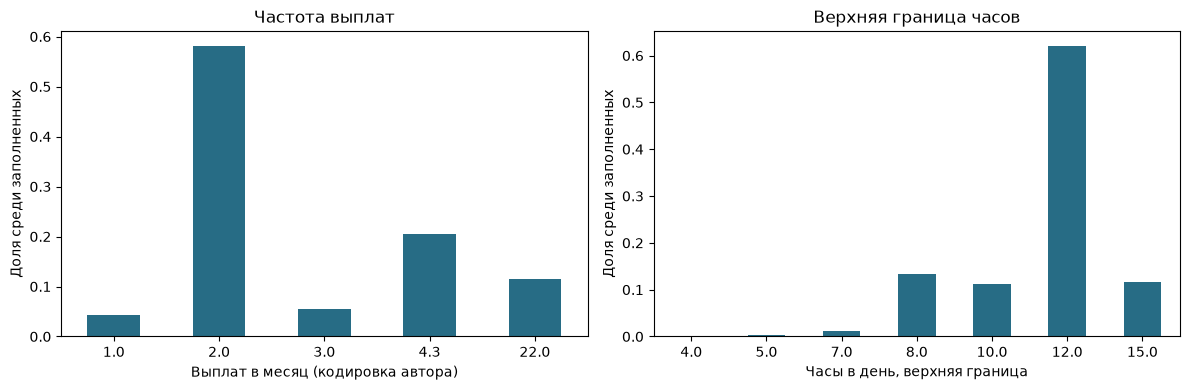

In [25]:
def numeric_card_features(part):
    output = pd.DataFrame(index=part.index)
    output["Выплат в месяц (кодировка автора)"] = clean_field(part["Частота выплат"]).map(PAY_PER_MONTH)
    for field, unit in [
        ("Количество рабочих часов в день", "Часы в день"),
        ("Количество рабочих дней в неделю", "Дни в неделю"),
        ("Длительность вахты", "Дни вахты"),
    ]:
        bounds = range_bounds(clean_field(part[field]))
        output[f"{unit}, нижняя граница"] = bounds["min"]
        output[f"{unit}, верхняя граница"] = bounds["max"]
    output["Просмотров всего"] = views(part["views_total"])
    today = clean_field(part["views_today"]).str.replace(r"^\(\+([\d ]+) сегодня\)$", r"\1", regex=True)
    output["Просмотров сегодня"] = pd.to_numeric(today.str.replace(" ", ""), errors="coerce")
    return output

features = numeric_card_features(approved)
numeric_rows = []
for field in features:
    number = features[field]
    for keys, part in [("Весь снимок", approved), *decision_rows.groupby(SEGMENT_KEYS)]:
        if keys != "Весь снимок" and field.startswith("Дни вахты"):
            continue
        sample = number.reindex(part.index).dropna()
        q1, median, q3 = sample.quantile([.25, .5, .75])
        numeric_rows.append(dict(
            field=field, segment=keys if isinstance(keys, str) else " × ".join(keys),
            n_total=len(part), max_value_share=sample.value_counts(normalize=True).max(),
            q1=q1, median=median, q3=q3, **lilliefors_row(sample),
        ))
numeric_tests = pd.concat([
    holm(group) for _, group in pd.DataFrame(numeric_rows).groupby("field", sort=False)
], ignore_index=True)
display(numeric_tests.loc[numeric_tests["segment"].eq("Весь снимок")])
display(numeric_tests.groupby(["field", "status_Holm"]).size().unstack(fill_value=0))

def info_normality_profile(profession, city):
    """Show the individual tests and quartiles for one agreed segment."""
    display(numeric_tests.loc[numeric_tests["segment"].eq(f"{profession} × {city}")])

info_normality_profile("Кассир", "Санкт-Петербург")

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (field, title) in zip(axes, [
    ("Выплат в месяц (кодировка автора)", "Частота выплат"),
    ("Часы в день, верхняя граница", "Верхняя граница часов"),
]):
    values = features.loc[decision_rows.index, field].dropna()
    values.value_counts(normalize=True).sort_index().plot.bar(ax=ax, color="#276c85")
    ax.set_title(title)
    ax.set_ylabel("Доля среди заполненных")
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 10. Что подтверждается по инфополям

- **Согласованные Core-поля доступны во всех 15 ячейках.** График, занятость, опыт
  и сфера деятельности заполнены на 100%. Частота выплат заполнена на 88,8–98,2%,
  у кассиров Санкт-Петербурга — на 93,6%. Поэтому формулировку «100% по всем
  Core-полям» уточняем. Доступность профессиональных признаков зависит от ячейки.
- **У числовых представлений выраженная дискретность.** На полном снимке и в
  проверках по ячейкам все выполненные диагностики Лиллиефорса отклоняют
  непрерывную нормаль после поправки Холма. Например, кодировка «2 выплаты в
  месяц» занимает 51,8% заполненных значений на полном снимке. Результат описывает
  наблюдаемые ответы карточек и их кодировки. Калибровка на непрерывной нормали
  даёт ориентировочные p для таких данных.
- **Инфополя подходят для подготовки базовой модели.** Заполняемость и вариативность
  проверяются по конкретным полям. Способность модели обобщать на новых работодателей
  проверяется на отдельной выборке. Допуск разрезов по целевой переменной показан в
  [копии зарплатного ноутбука](salary_segment_normality.ipynb).
